In [1]:
import numpy as np
import scipy.stats

import matplotlib.pyplot as plt

In [2]:
title = "# Sampling 1: Exercises"
# Print title and setup TeX defs for both KaTeX and MathJax
import bayesian_stats_course_tools
bayesian_stats_course_tools.misc.display_markdown_and_setup_tex(title)

import matplotlib.style
matplotlib.style.use("bayesian_stats_course_tools.light")

# Sampling 1: Exercises

<!-- Define LaTeX macros -->
$\def\E{\operatorname{E}}$
$\def\Var{\operatorname{Var}}$
$\def\Cov{\operatorname{Cov}}$
$\def\dd{\mathrm{d}}$
$\def\ee{\mathrm{e}}$
$\def\Norm{\mathcal{N}}$
$\def\Uniform{\mathcal{U}}$
$\def\GP{\mathcal{GP}}$

<!-- MathJax needs them to be defined again for the non-inline environment -->
$$\def\E{\operatorname{E}}$$
$$\def\Var{\operatorname{Var}}$$
$$\def\Cov{\operatorname{Cov}}$$
$$\def\dd{\mathrm{d}}$$
$$\def\ee{\mathrm{e}}$$
$$\def\Norm{\mathcal{N}}$$
$$\def\Uniform{\mathcal{U}}$$
$$\def\GP{\mathcal{GP}}$$

### Exercise

Implement your own rejection sampling routine and test it with different target and proposal distributions.

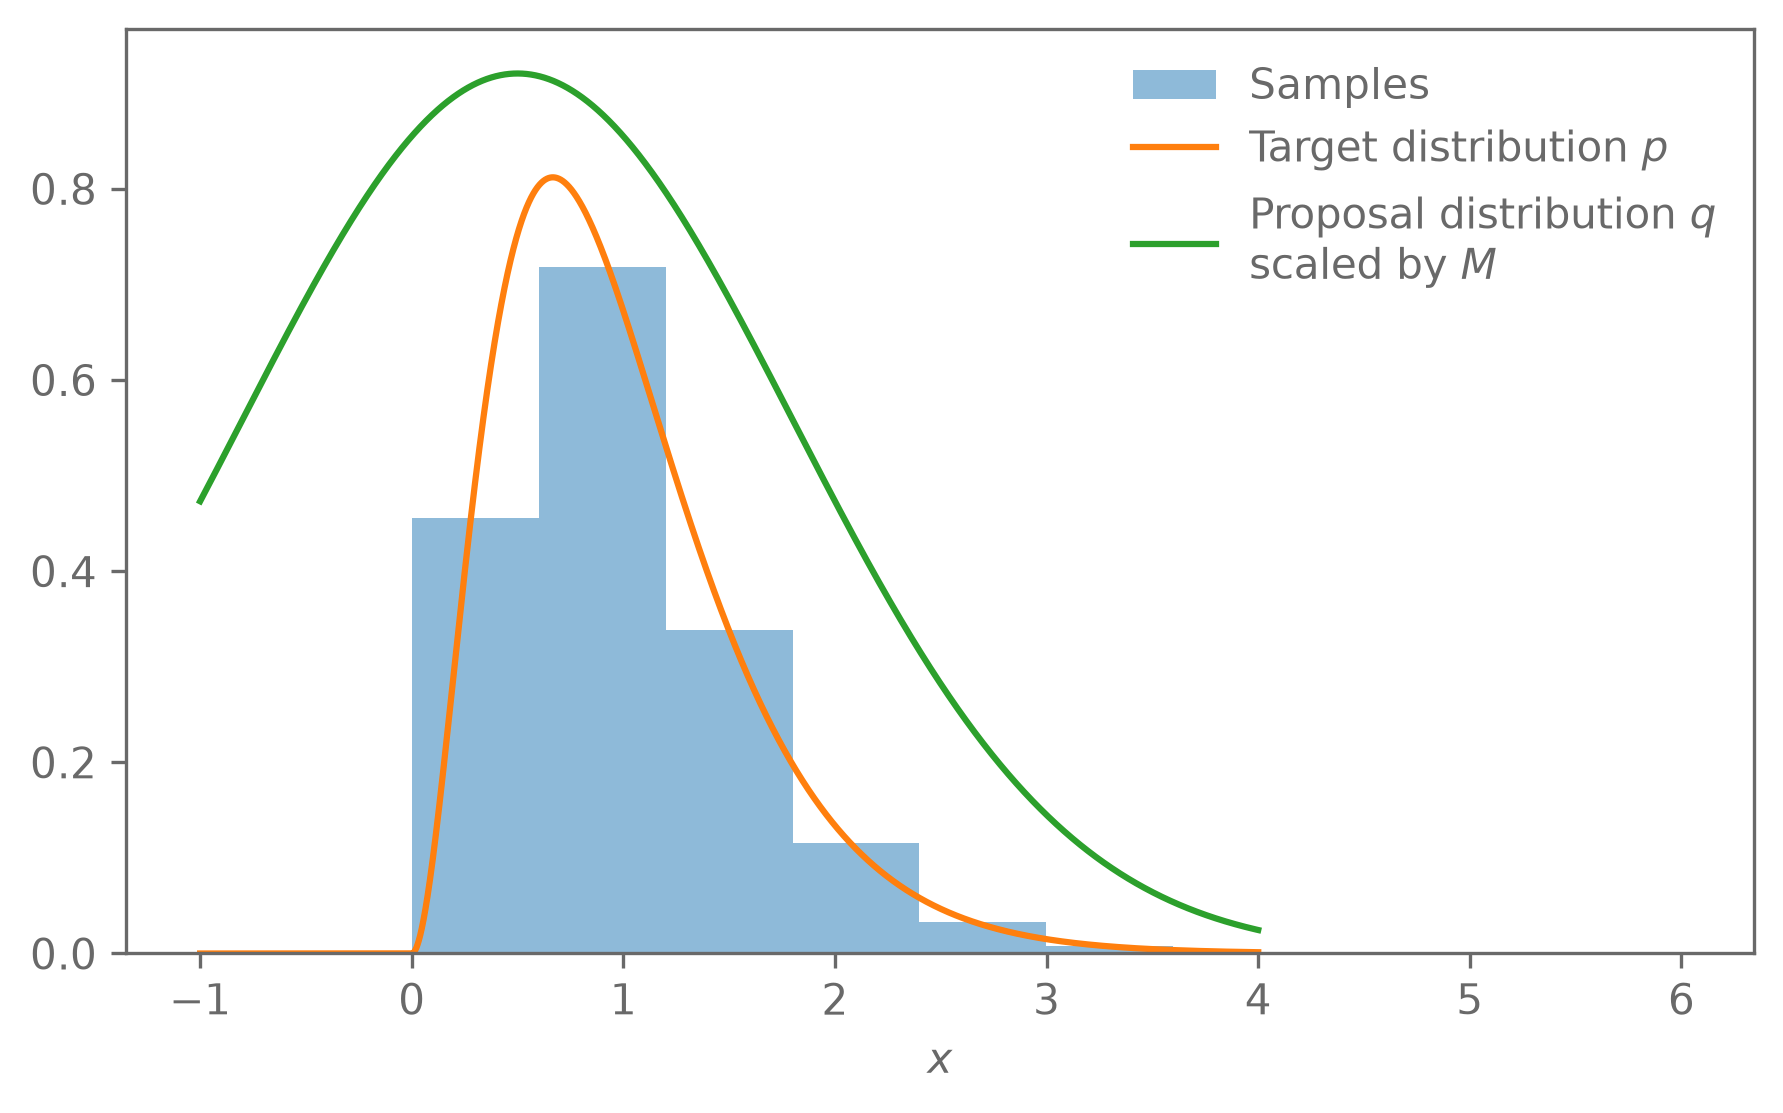

In [3]:
def sample(p,M,q,N):
    x = q.rvs(size=N)
    for x in x:
        u=np.random.rand()
        if u*M*q.pdf(x)<p.pdf(x):
            yield x


p = scipy.stats.gamma(a=3, scale=1/3)
q = scipy.stats.norm(loc=0.5, scale=1.3)
M = 3


samples = []
for x in sample(p,M,q,100000):
    samples.append(x)

grid = np.linspace(-1, 4, 100000)

plt.hist(np.array(samples), density=True, alpha=0.5, label="Samples")
plt.plot(grid, p.pdf(grid), label="Target distribution $p$")
plt.plot(grid, M*q.pdf(grid), label="Proposal distribution $q$\nscaled by $M$")
plt.xlabel("$x$")
plt.legend(frameon=False);

### Exercise

- Implement Metropolis-Hastings for $n$ dimensional distributions
    - Sample from a 2D Gaussian (code on the next slide)
    - Plot the samples in the chain. How do the samples depend on the starting position?
- Show that Metropolis-Hastings satisfies detailed balance
    - Hint: $T(x|y) = q(x|y)\min(1, a)$

In [ ]:
# Define variances and correlation
sigma_x = 1
sigma_y = 2
rho = 0.7

# Define mean and covariance
mean = np.array([1, 0.5])
cov = np.array([[sigma_x**2, sigma_x*sigma_y*rho],
                [sigma_x*sigma_y*rho, sigma_y**2]])

# Create distribution object
bivariate_normal = scipy.stats.multivariate_normal(mean=mean, cov=cov)

# Sample 1000 points. Do this with your MCMC implementation instead!
samples = bivariate_normal.rvs(size=1000)

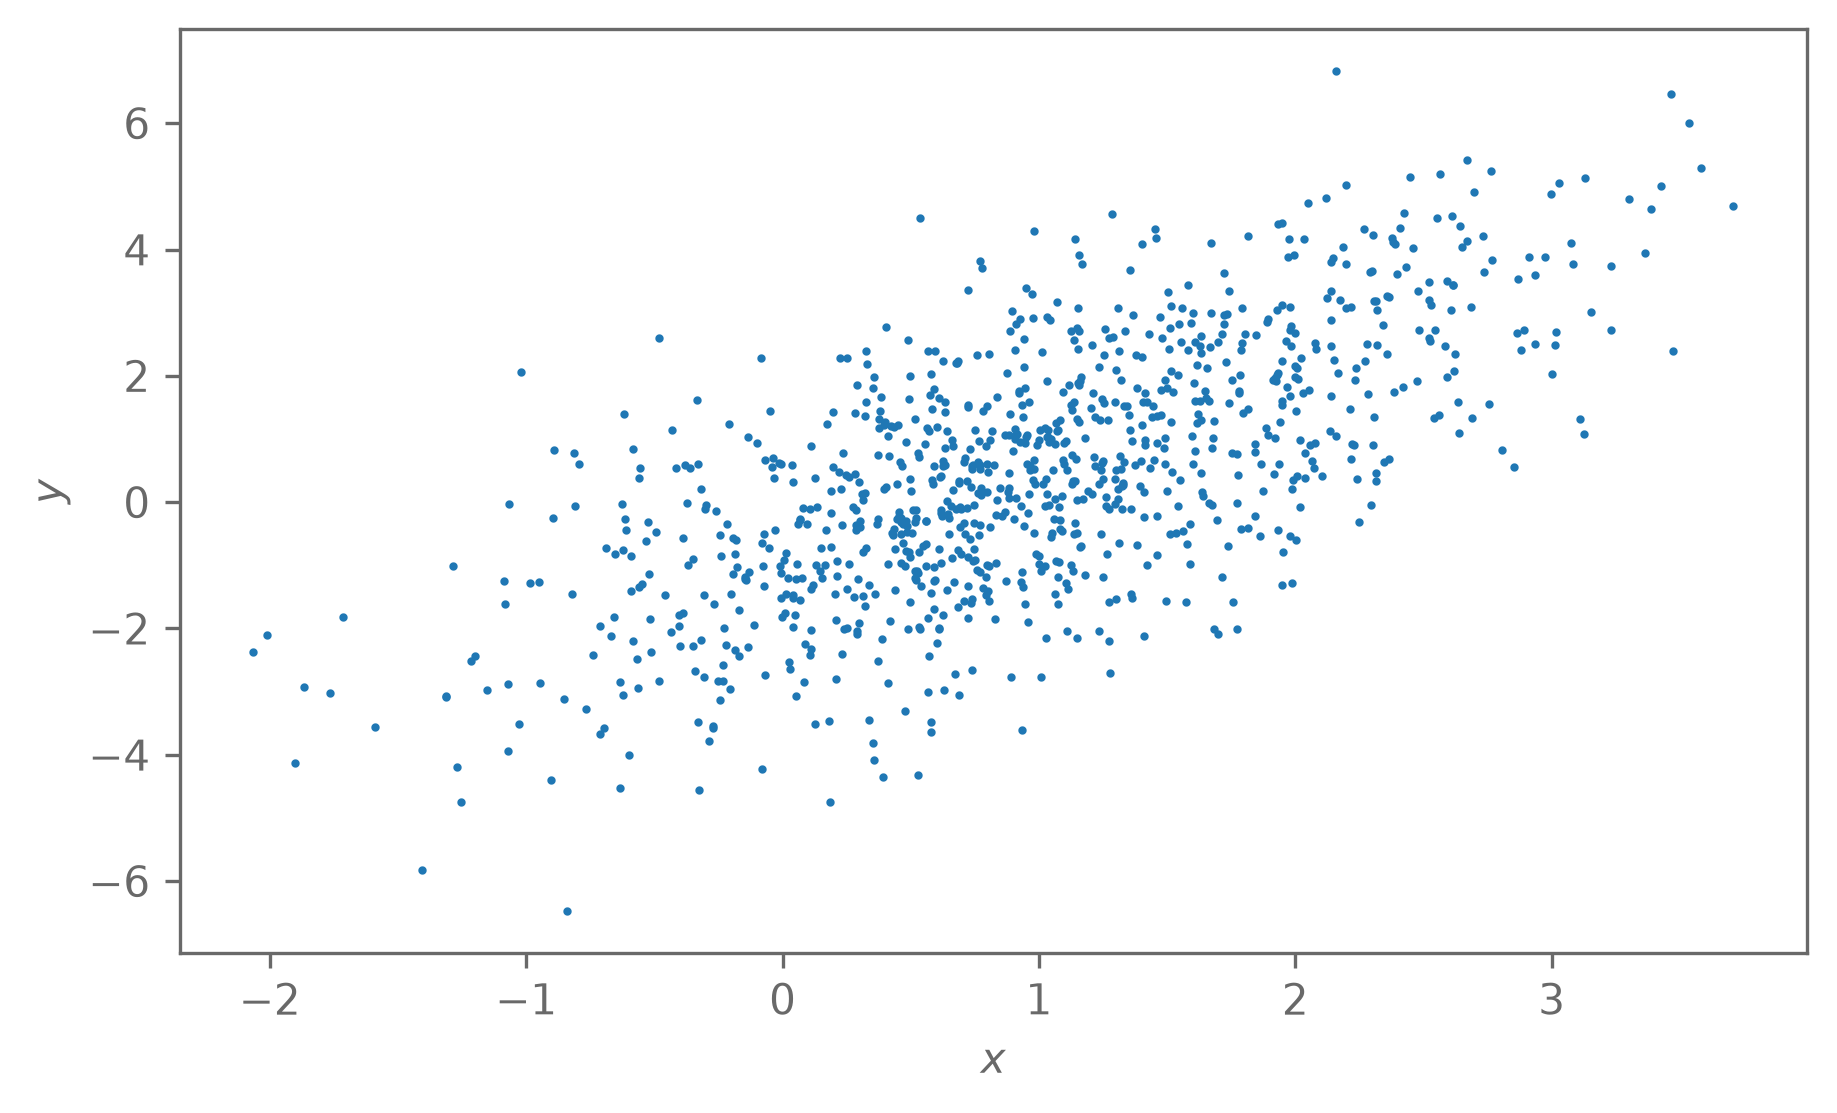

In [4]:
plt.scatter(*samples.T, s=1)
plt.ylabel("$y$")
plt.xlabel("$x$");

In [ ]:
q = partial(scipy.stats.norm, scale=1)


def transition_probability(x,y,p,q):
    return (p(x)*q(y,x))/(p(y)*q(x,y))


def sample_metropolis_hastings(x_old,N):
    for i range(N):
        x_new=x_old+q(x_new,x_old)